# 06 · Segmentación de países (R5 · P5)
**Proyecto semestral · Sala de crisis COVID-19 · Gestión de Datos IN1232C · 2026-2**

Requiere `03_dw_estrella` y `05_fuentes_externas` (usa `dim_pais`).

**P5 · ¿Qué grupos de países tuvieron pandemias parecidas?**

1. Armar la **incidencia semanal por 100.000** de cada país desde el DW.
2. **Normalizar** cada curva por su propio máximo: así se compara la **forma** de la pandemia (cuándo fueron las olas), no su tamaño.
3. Agrupar con **k-means** y elegir el número de grupos con el **codo** y el **coeficiente de silueta**.
4. Describir cada grupo y ver **en cuál está Chile**.

## Setup

In [1]:
import os
import shutil
import sqlite3
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 2)

from google.colab import drive
drive.mount('/content/drive')

PROYECTO = '/content/drive/MyDrive/proyecto-gestion-datos-2026'
LIMPIOS = os.path.join(PROYECTO, 'data', 'clean')
shutil.copy(os.path.join(PROYECTO, 'data', 'dw', 'covid_dw.db'), '/content/covid_dw.db')
dw = sqlite3.connect('/content/covid_dw.db')

## 1 · Incidencia semanal por país
Igual que en `04`: acumulados por país y día desde el DW (sin el archivo defectuoso del 23-may-2022), nuevos = diferencia con el día anterior (los negativos cuentan como 0) y luego suma por semana (domingo a domingo).

Entran los países con **1 millón de habitantes o más** y **índice de calidad ≥ 80**, para que una curva no la deforme el ruido de un país muy pequeño o con datos poco confiables.

In [2]:
pais_dia = pd.read_sql("""
    SELECT t.pais, d.fecha, SUM(f.casos_acum) AS casos_acum
    FROM fact_covid f
    JOIN dim_fecha d      ON d.fecha_key = f.fecha_key
    JOIN dim_territorio t ON t.territorio_key = f.territorio_key
    WHERE f.archivo_defectuoso = 0
    GROUP BY t.pais, d.fecha
""", dw)
dim_pais = pd.read_sql('SELECT pais, poblacion, region_bm, grupo_ingreso, indice_calidad FROM dim_pais', dw)

pais_dia['fecha'] = pd.to_datetime(pais_dia['fecha'])
pais_dia = pais_dia.sort_values(['pais', 'fecha'])
pais_dia['casos_nuevos'] = pais_dia.groupby('pais')['casos_acum'].diff().clip(lower=0)

semana = pais_dia.set_index('fecha').groupby('pais')['casos_nuevos'].resample('W-SUN').sum().reset_index()
semana = semana[(semana['fecha'] >= '2020-03-01') & (semana['fecha'] <= '2023-03-05')]
semana = semana.merge(dim_pais, on='pais')
semana = semana[(semana['poblacion'] >= 1000000) & (semana['indice_calidad'] >= 80)]
semana['incidencia'] = semana['casos_nuevos'] / semana['poblacion'] * 100000

# Matriz: una fila por país, una columna por semana
M = semana.pivot_table(index='pais', columns='fecha', values='incidencia').fillna(0)
M = M[M.max(axis=1) > 0]
print('Países:', M.shape[0], '| semanas:', M.shape[1])

Países: 156 | semanas: 158


## 2 · Normalizar: comparar la forma, no el tamaño
Cada curva se divide por su máximo: la semana peor de cada país vale 1. Sin esto, k-means separaría a los países por cuánto testearon (países con muchos casos vs. pocos) y no por **cuándo** les llegaron las olas.

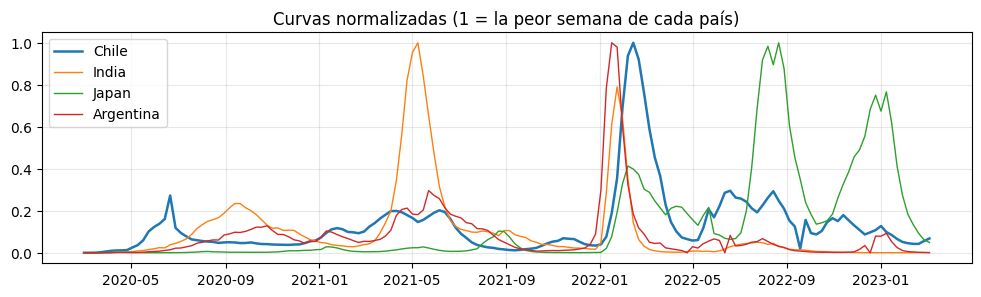

In [3]:
N = M.div(M.max(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(12, 3))
for pais in ['Chile', 'India', 'Japan', 'Argentina']:
    ax.plot(N.columns, N.loc[pais], label=pais, linewidth=1.8 if pais == 'Chile' else 1)
ax.set_title('Curvas normalizadas (1 = la peor semana de cada país)')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 3 · ¿Cuántos grupos? Codo y silueta

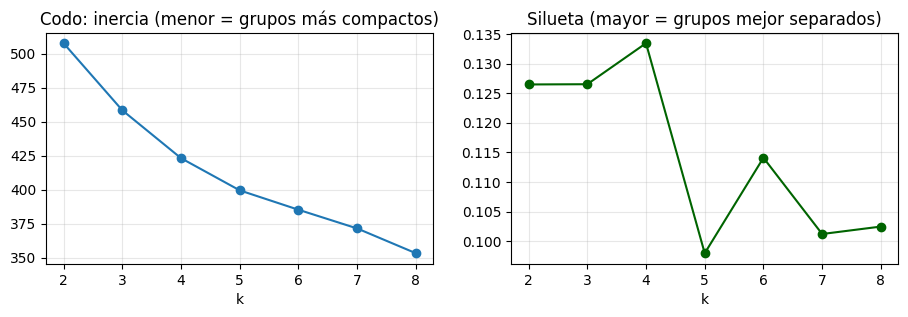

k elegido (máxima silueta): 4


,inercia,silueta
k,,
2,507.85,0.13
3,458.50,0.13
4,423.24,0.13
5,399.55,0.10
6,385.29,0.11
7,371.51,0.10
8,353.28,0.10


In [4]:
filas = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(N)
    filas.append({'k': k, 'inercia': km.inertia_, 'silueta': silhouette_score(N, km.labels_)})
eleccion = pd.DataFrame(filas).set_index('k')

fig, axes = plt.subplots(1, 2, figsize=(11, 3))
axes[0].plot(eleccion.index, eleccion['inercia'], marker='o')
axes[0].set_title('Codo: inercia (menor = grupos más compactos)')
axes[1].plot(eleccion.index, eleccion['silueta'], marker='o', color='darkgreen')
axes[1].set_title('Silueta (mayor = grupos mejor separados)')
for ax in axes:
    ax.set_xlabel('k')
    ax.grid(alpha=0.3)
plt.show()

k = eleccion['silueta'].idxmax()
print('k elegido (máxima silueta):', k)
eleccion.round(3)

## 4 · Los grupos
Se numeran por la fecha del **peor momento de la curva promedio** del grupo (grupo 1 = el que tuvo su peor momento primero).

In [5]:
km = KMeans(n_clusters=k, n_init=10, random_state=42).fit(N)
etiqueta = pd.Series(km.labels_, index=N.index)

# Perfil de cada grupo: curva promedio, semana del máximo y % de sus casos en cada año
filas = []
for c in range(k):
    miembros = etiqueta[etiqueta == c].index
    curva = N.loc[miembros].mean()
    casos_anio = M.loc[miembros].T.groupby(M.columns.year).sum().T
    pct_anio = casos_anio.div(casos_anio.sum(axis=1), axis=0).mean() * 100
    filas.append({'cluster': c, 'países': len(miembros), 'semana_peor': curva.idxmax().date(),
                  '% casos 2020': pct_anio.get(2020, 0), '% casos 2021': pct_anio.get(2021, 0),
                  '% casos 2022-23': pct_anio.get(2022, 0) + pct_anio.get(2023, 0),
                  'incidencia_total_x100k': M.loc[miembros].sum(axis=1).median()})
perfil = pd.DataFrame(filas).sort_values('semana_peor')
perfil['grupo'] = range(1, k + 1)
renumerar = dict(zip(perfil['cluster'], perfil['grupo']))
grupo = etiqueta.map(renumerar)
perfil = perfil.set_index('grupo').drop(columns='cluster')
print('Chile está en el grupo', grupo['Chile'])
perfil.round(0)

Chile está en el grupo 3


,países,semana_peor,% casos 2020,% casos 2021,% casos 2022-23,incidencia_total_x100k
grupo,,,,,,
1,28,2021-08-01,20.0,58.0,22.0,3337.0
2,52,2022-01-09,20.0,54.0,26.0,467.0
3,59,2022-01-30,15.0,36.0,48.0,20209.0
4,17,2022-03-20,1.0,17.0,82.0,38131.0


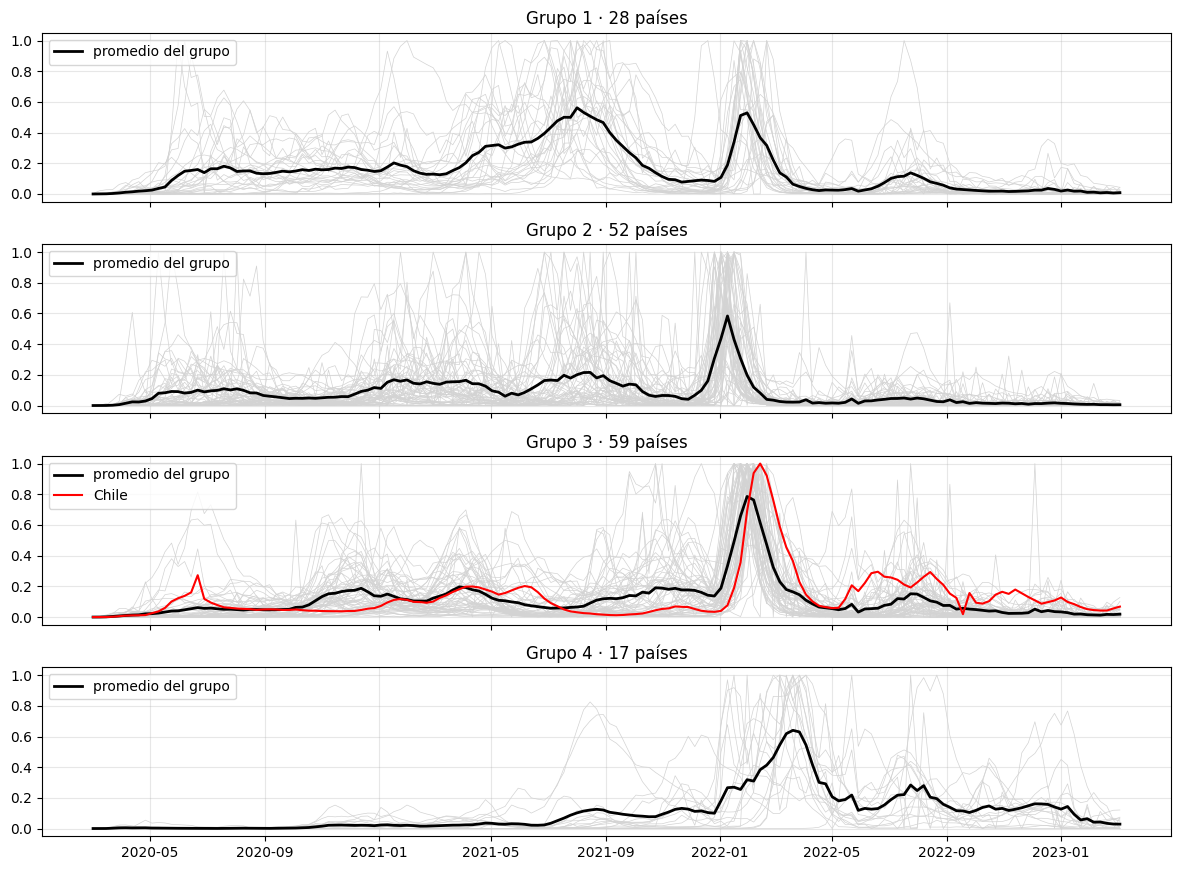

In [6]:
fig, axes = plt.subplots(k, 1, figsize=(12, 2.2 * k), sharex=True)
for g, ax in zip(range(1, k + 1), axes):
    miembros = grupo[grupo == g].index
    for pais in miembros:
        ax.plot(N.columns, N.loc[pais], color='lightgray', linewidth=0.5)
    ax.plot(N.columns, N.loc[miembros].mean(), color='black', linewidth=2, label='promedio del grupo')
    if 'Chile' in miembros:
        ax.plot(N.columns, N.loc['Chile'], color='red', linewidth=1.5, label='Chile')
    ax.set_title(f'Grupo {g} · {len(miembros)} países')
    ax.legend(loc='upper left')
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [7]:
sudamerica = ['Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Paraguay', 'Peru', 'Uruguay', 'Venezuela']
resultado = pd.DataFrame({'grupo': grupo}).join(dim_pais.set_index('pais')[['region_bm', 'grupo_ingreso']])
print('Sudamérica:')
print(resultado.loc[[p for p in sudamerica if p in resultado.index], 'grupo'].sort_values().to_string())

for g in range(1, k + 1):
    miembros = sorted(resultado[resultado['grupo'] == g].index)
    print(f'\nGrupo {g} ({len(miembros)}):', ', '.join(miembros))

Sudamérica:
pais
Colombia     1
Venezuela    1
Bolivia      2
Argentina    2
Chile        3
Ecuador      3
Paraguay     3
Brazil       3
Peru         3
Uruguay      3

Grupo 1 (28): Afghanistan, Algeria, Bangladesh, Burma, Cambodia, Colombia, Cuba, Guatemala, Haiti, Honduras, India, Indonesia, Iran, Iraq, Kazakhstan, Libya, Morocco, Nepal, Nicaragua, Oman, Pakistan, South Africa, Sri Lanka, Timor-Leste, Tunisia, United Arab Emirates, Uzbekistan, Venezuela

Grupo 2 (52): Angola, Argentina, Benin, Bolivia, Botswana, Burkina Faso, Burundi, Cameroon, Canada, Central African Republic, Chad, Congo (Brazzaville), Congo (Kinshasa), Cote d'Ivoire, Dominican Republic, Equatorial Guinea, Eritrea, Eswatini, Ethiopia, Gabon, Gambia, Ghana, Guinea, Guinea-Bissau, Ireland, Jamaica, Kenya, Kyrgyzstan, Lesotho, Liberia, Madagascar, Malawi, Mali, Mauritania, Mozambique, Namibia, Niger, Nigeria, Philippines, Qatar, Rwanda, Senegal, Sierra Leone, Somalia, South Sudan, Tajikistan, Tanzania, Togo, Uganda, Y

In [8]:
# ¿Qué tipo de países hay en cada grupo? (región del Banco Mundial y grupo de ingreso)
pd.crosstab(resultado['grupo'], resultado['grupo_ingreso'])[['Bajo', 'Medio bajo', 'Medio alto', 'Alto']]

grupo_ingreso,Bajo,Medio bajo,Medio alto,Alto
grupo,,,,
1,1,14,11,2
2,21,21,7,3
3,2,4,20,33
4,0,1,5,10


**Interpretación (P5):** la silueta es máxima con **4 grupos**, aunque baja (0,13): las curvas se parecen entre sí y los grupos se traslapan, así que son tendencias, no categorías rígidas.

| Grupo | Qué lo caracteriza | Ejemplos |
|---|---|---|
| **1 · Golpe de Delta (2021)** | Su peor semana fue en ago-2021; el 58 % de sus casos fue en 2021 | India, Indonesia, Irán, Sudáfrica, Colombia, Cuba, Venezuela |
| **2 · Olas de 2021 y ómicron breve** | El 54 % de sus casos fue en 2021, con un pico corto de ómicron en ene-2022; incidencia total muy baja (poco testeo) | Casi toda África subsahariana, Argentina, Bolivia, Canadá, Filipinas |
| **3 · Olas sostenidas, ómicron la mayor** | Olas en 2020 y 2021, y la peor en ene-2022; el 48 % de sus casos en 2022-23 | Europa, EE.UU., México, **Chile**, Brasil, Perú, Uruguay, Ecuador, Paraguay |
| **4 · Contención temprana y ómicron tardío** | Casi nada en 2020 y el 82 % de sus casos en 2022-23, con su peor semana en mar-2022 | Australia, Nueva Zelanda, China, Japón, Corea del Sur, Taiwán, Vietnam, Alemania |

**Chile está en el grupo 3**, junto a la mayoría de Sudamérica y Europa: varias olas grandes y ómicron como la peor. Los grupos 3 y 4 son sobre todo de ingreso alto, y el 2 de ingreso bajo y medio bajo: la forma de la curva también refleja cuánto testeó cada país.

## 5 · Guardar
La asignación de grupos queda en el DW (`segmentacion_paises`) y en la capa limpia, para el tablero y el informe.

In [9]:
salida = resultado.reset_index().rename(columns={'index': 'pais'})[['pais', 'grupo']]
salida.to_sql('segmentacion_paises', dw, if_exists='replace', index=False)
salida.to_parquet(os.path.join(LIMPIOS, 'segmentacion_paises.parquet'), index=False)
dw.close()
shutil.copy('/content/covid_dw.db', os.path.join(PROYECTO, 'data', 'dw', 'covid_dw.db'))
print('Guardado:', len(salida), 'países')

Guardado: 156 países
